<a href="https://colab.research.google.com/github/srilekhamallipudi-dotcom/Intelligent_Loan_Risk_Assessment/blob/main/ML_intelligent_Loan__risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving credit_risk_dataset.csv to credit_risk_dataset (1).csv


In [ ]:
df = pd.read_csv("credit_risk_dataset.csv")

In [ ]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
df.shape

(32581, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
df.duplicated().sum()

np.int64(165)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(32416, 12)

In [ ]:
df['person_emp_length'] = df['person_emp_length'].fillna(
    df['person_emp_length'].median()
)

df['loan_int_rate'] = df['loan_int_rate'].fillna(
    df['loan_int_rate'].median()
)

In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


In [ ]:
df.describe()


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32416.000000,3.241600e+04,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000
mean,27.747008,6.609164e+04,4.768880,9593.845632,11.014662,0.218688,0.170250,5.811297
std,6.354100,6.201558e+04,4.090411,6322.730241,3.083050,0.413363,0.106812,4.059030
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.000000,5000.000000,8.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.000000,12250.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
print("Age <= 0:", (df['person_age'] <= 0).sum())
print("Income <= 0:", (df['person_income'] <= 0).sum())
print("Loan Amount <= 0:", (df['loan_amnt'] <= 0).sum())
print("Interest Rate <= 0:", (df['loan_int_rate'] <= 0).sum())

Age <= 0: 0
Income <= 0: 0
Loan Amount <= 0: 0
Interest Rate <= 0: 0


In [ ]:
num_cols = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]



In [ ]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, ":", count, "outliers")

person_age : 1491 outliers
person_income : 1478 outliers
person_emp_length : 852 outliers
loan_amnt : 1679 outliers
loan_int_rate : 70 outliers
loan_percent_income : 650 outliers
cb_person_cred_hist_length : 1139 outliers


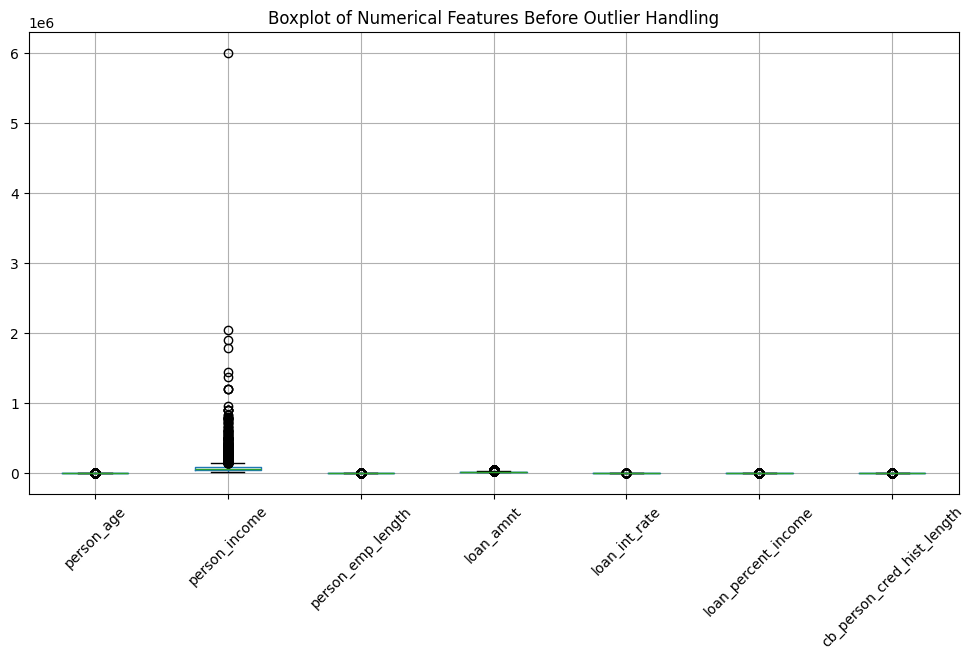

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
df[num_cols].boxplot()
plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features Before Outlier Handling")
plt.show()

In [ ]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower, upper=upper)

In [ ]:

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, ":", count, "outliers")


person_age : 0 outliers
person_income : 0 outliers
person_emp_length : 0 outliers
loan_amnt : 0 outliers
loan_int_rate : 0 outliers
loan_percent_income : 0 outliers
cb_person_cred_hist_length : 0 outliers


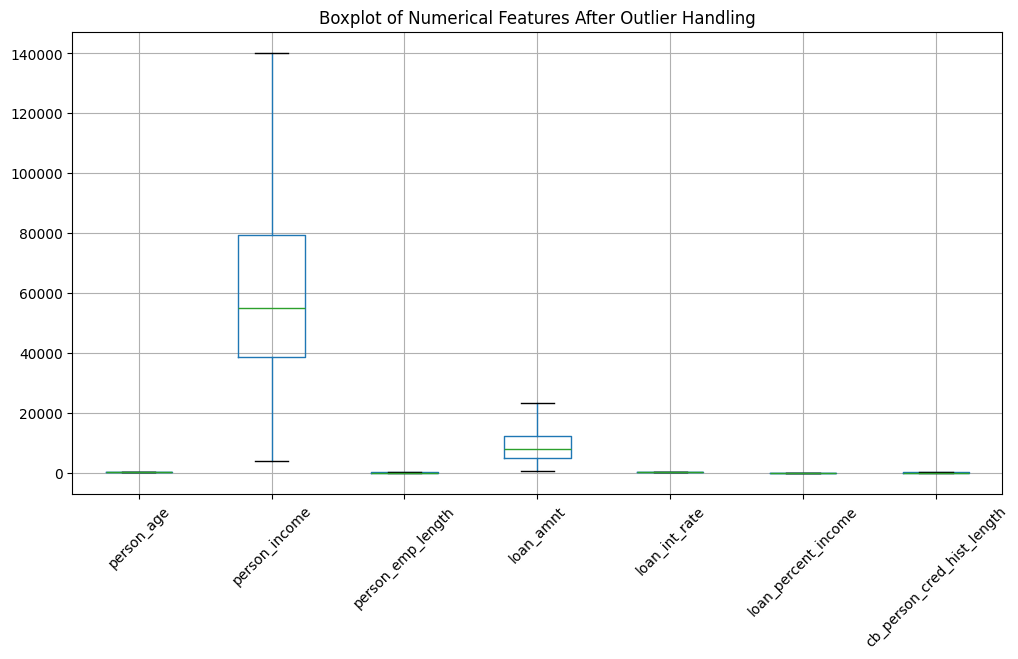

In [ ]:
plt.figure(figsize=(12, 6))
df[num_cols].boxplot()
plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features After Outlier Handling")
plt.show()

In [ ]:
cat_cols = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

In [ ]:
for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts())


 person_home_ownership
person_home_ownership
RENT        16378
MORTGAGE    13369
OWN          2563
OTHER         106
Name: count, dtype: int64

 loan_intent
loan_intent
EDUCATION            6411
MEDICAL              6042
VENTURE              5682
PERSONAL             5498
DEBTCONSOLIDATION    5189
HOMEIMPROVEMENT      3594
Name: count, dtype: int64

 loan_grade
loan_grade
A    10703
B    10387
C     6438
D     3620
E      963
F      241
G       64
Name: count, dtype: int64

 cb_person_default_on_file
cb_person_default_on_file
N    26686
Y     5730
Name: count, dtype: int64


In [ ]:
# Check target variable distribution

print(df['loan_status'].value_counts())
print("\nTarget Distribution (%):")
print(df['loan_status'].value_counts(normalize=True) * 100)

loan_status
0    25327
1     7089
Name: count, dtype: int64

Target Distribution (%):
loan_status
0    78.13117
1    21.86883
Name: proportion, dtype: float64


In [ ]:
# Separate features and target

X = df.drop('loan_status', axis=1)
y = df['loan_status']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (32416, 11)
y shape: (32416,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (25932, 11)
X_test: (6484, 11)
y_train: (25932,)
y_test: (6484,)


In [ ]:
# Encode loan_grade using ordinal encoding

grade_mapping = {
    'A': 0,
    'B': 1,
    'C': 2,
    'D': 3,
    'E': 4,
    'F': 5,
    'G': 6
}

X_train['loan_grade'] = X_train['loan_grade'].map(grade_mapping)
X_test['loan_grade'] = X_test['loan_grade'].map(grade_mapping)

print(X_train['loan_grade'].value_counts().sort_index())

loan_grade
0    8584
1    8285
2    5173
3    2889
4     765
5     188
6      48
Name: count, dtype: int64


In [ ]:
# One-Hot Encoding for categorical columns

X_train = pd.get_dummies(
    X_train,
    columns=[
        'person_home_ownership',
        'loan_intent',
        'cb_person_default_on_file'
    ],
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=[
        'person_home_ownership',
        'loan_intent',
        'cb_person_default_on_file'
    ],
    drop_first=True
)

# Make sure train and test have the same columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("\nColumns:")
print(X_train.columns.tolist())

X_train shape: (25932, 17)
X_test shape: (6484, 17)

Columns:
['person_age', 'person_income', 'person_emp_length', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'cb_person_default_on_file_Y']


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (25932, 17)
X_test_scaled shape: (6484, 17)


In [ ]:
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
loan_status
0    20261
1     5671
Name: count, dtype: int64


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("After SMOTE:")
print(y_train_smote.value_counts())

After SMOTE:
loan_status
0    20261
1    20261
Name: count, dtype: int64


In [ ]:
print("X_train_smote shape:", X_train_smote.shape)
print("y_train_smote shape:", y_train_smote.shape)

print("X_test_scaled shape:", X_test_scaled.shape)
print("y_test shape:", y_test.shape)


X_train_smote shape: (40522, 17)
y_train_smote shape: (40522,)
X_test_scaled shape: (6484, 17)
y_test shape: (6484,)


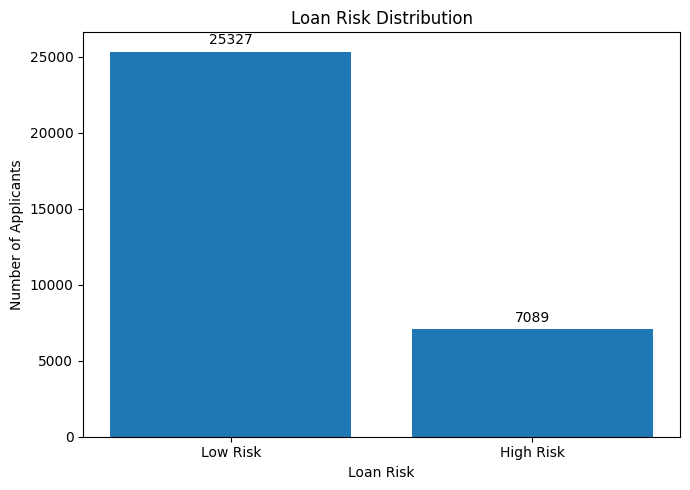

In [ ]:
import matplotlib.pyplot as plt

# Loan Risk Distribution
risk_counts = df['loan_status'].value_counts().sort_index()

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ['Low Risk', 'High Risk'],
    [risk_counts.get(0, 0), risk_counts.get(1, 0)]
)

plt.title('Loan Risk Distribution')
plt.xlabel('Loan Risk')
plt.ylabel('Number of Applicants')
plt.bar_label(bars, padding=3)

plt.tight_layout()
plt.savefig('loan_risk_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_smote, y_train_smote)

y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression Results")
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

Logistic Regression Results
Accuracy : 0.7925663170882171
Precision: 0.5171281088690756
Recall   : 0.7771509167842031
F1 Score : 0.6210200056353903


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_smote, y_train_smote)

y_pred_rf = rf_model.predict(X_test_scaled)

print("Random Forest Results")
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

Random Forest Results
Accuracy : 0.9307526218383714
Precision: 0.9345291479820628
Recall   : 0.7348377997179125
F1 Score : 0.822739834188709


In [ ]:
# Install XGBoost if required
!pip install xgboost

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train_smote, y_train_smote)

y_pred_xgb = xgb_model.predict(X_test_scaled)

print("XGBoost Results")
print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_xgb, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_xgb, zero_division=0))

XGBoost Results
Accuracy : 0.9359962985811228
Precision: 0.9546690843155031
Recall   : 0.7425952045133991
F1 Score : 0.8353827846092821


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model, X_test_data, y_true, model_name):
    """
    Evaluates a trained classifier and prints key performance metrics.
    """
    # Predict values
    y_pred = model.predict(X_test_data)

    # Calculate metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    # Print results
    print(f"=== {model_name} Results ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}\n")

    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1_score": f1
    }

# Evaluate the models
lr_results = evaluate_model(
    lr_model, X_test_scaled, y_test, "Logistic Regression"
)

rf_results = evaluate_model(
    rf_model, X_test_scaled, y_test, "Random Forest"
)

xgb_results = evaluate_model(
    xgb_model, X_test_scaled, y_test, "XGBoost"
)

=== Logistic Regression Results ===
Accuracy : 0.7926
Precision: 0.5171
Recall   : 0.7772
F1 Score : 0.6210

=== Random Forest Results ===
Accuracy : 0.9308
Precision: 0.9345
Recall   : 0.7348
F1 Score : 0.8227

=== XGBoost Results ===
Accuracy : 0.9360
Precision: 0.9547
Recall   : 0.7426
F1 Score : 0.8354



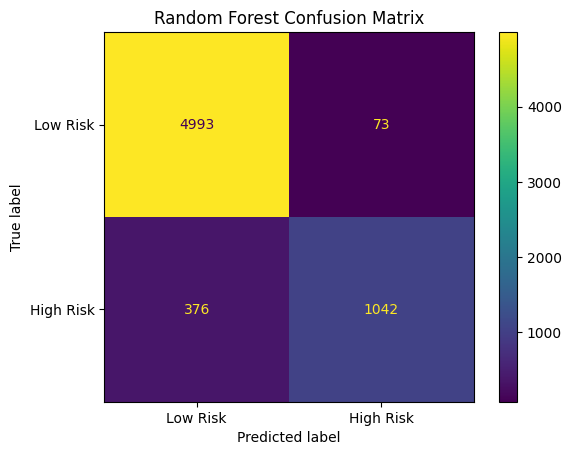

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low Risk', 'High Risk']
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

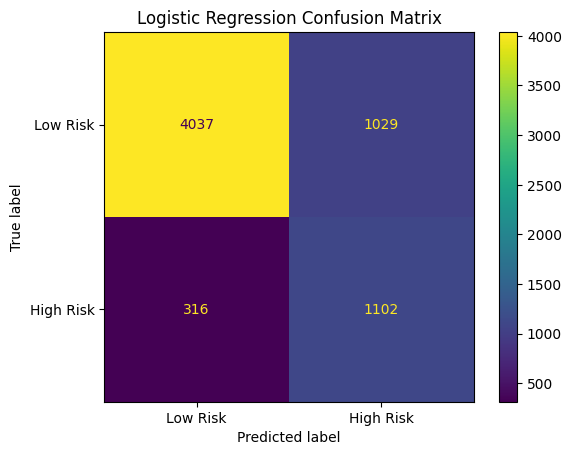

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low Risk', 'High Risk']
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

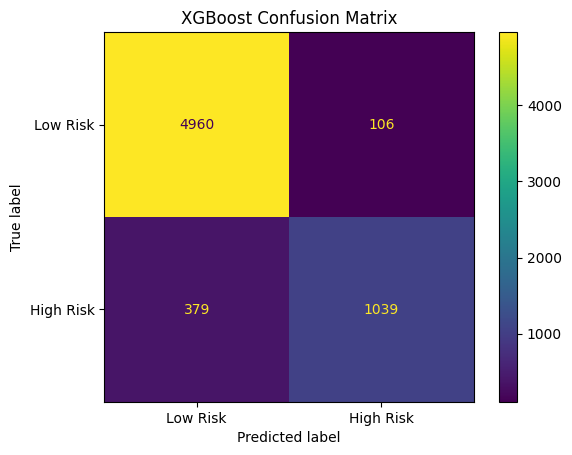

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low Risk', 'High Risk']
)

disp.plot()
plt.title("XGBoost Confusion Matrix")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
loan_percent_income            0.194242
loan_grade                     0.174222
person_income                  0.142839
loan_int_rate                  0.105124
loan_amnt                      0.070467
person_emp_length              0.061220
person_home_ownership_RENT     0.057698
person_age                     0.051478
cb_person_cred_hist_length     0.047514
person_home_ownership_OWN      0.016383
loan_intent_HOMEIMPROVEMENT    0.016256
cb_person_default_on_file_Y    0.013866
loan_intent_VENTURE            0.013778
loan_intent_EDUCATION          0.013122
loan_intent_PERSONAL           0.011336
loan_intent_MEDICAL            0.009685
person_home_ownership_OTHER    0.000770
dtype: float64


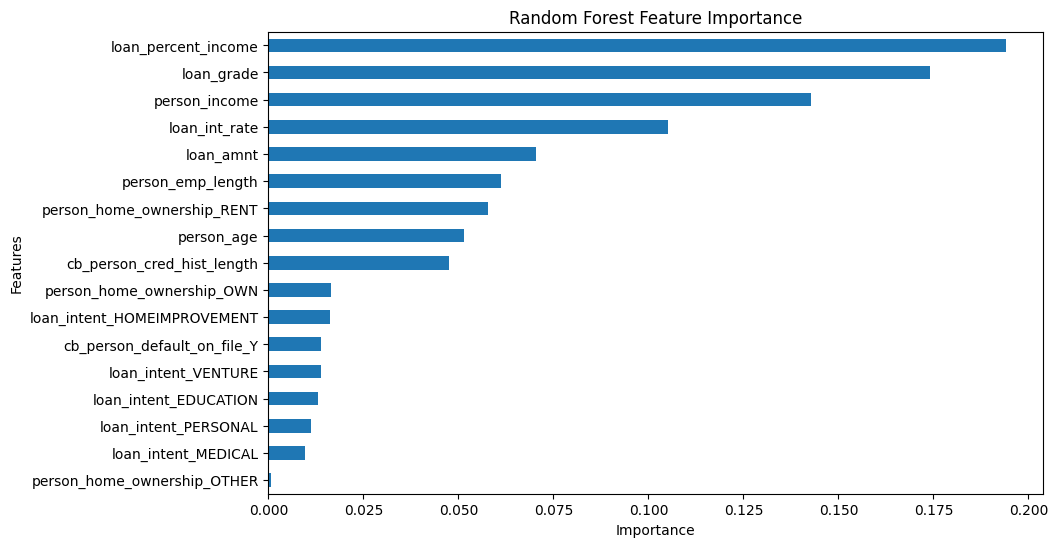

In [ ]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind='barh')

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [ ]:
import joblib

joblib.dump(rf_model, "random_forest_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Random Forest model and scaler saved successfully!")

Random Forest model and scaler saved successfully!


In [ ]:
# New Loan Applicant

sample_data = pd.DataFrame({
    'person_age': [25],
    'person_income': [50000],
    'person_home_ownership': ['RENT'],
    'person_emp_length': [3],
    'loan_intent': ['EDUCATION'],
    'loan_grade': ['B'],
    'loan_amnt': [10000],
    'loan_int_rate': [10.5],
    'loan_percent_income': [0.20],
    'cb_person_default_on_file': ['N'],
    'cb_person_cred_hist_length': [4]
})

# Encode loan grade
sample_data['loan_grade'] = sample_data['loan_grade'].map(grade_mapping)

# One-hot encoding
sample_data = pd.get_dummies(
    sample_data,
    columns=[
        'person_home_ownership',
        'loan_intent',
        'cb_person_default_on_file'
    ],
    drop_first=True
)

# Match training columns
sample_data = sample_data.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Scale
sample_scaled = scaler.transform(sample_data)

# Prediction
prediction = rf_model.predict(sample_scaled)

if prediction[0] == 1:
    print("Loan Status: HIGH RISK")
else:
    print("Loan Status: LOW RISK")

Loan Status: LOW RISK


In [ ]:
!pip install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 84.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 114.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit]


In [ ]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import base64
import os
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix


# ============================================================
# PAGE CONFIG
# ============================================================

st.set_page_config(
    page_title="Intelligent Loan Risk Assessment",
    page_icon="🏦",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ============================================================
# LOAD MODEL FILES
# ============================================================

rf_model = joblib.load("/content/random_forest_model.pkl")
scaler = joblib.load("/content/scaler.pkl")
eval_data = joblib.load("/content/rf_evaluation.pkl")


# ============================================================
# LOAN GRADE MAPPING
# IMPORTANT:
# Defined globally so BOTH Prediction and What-If can use it.
# ============================================================

grade_mapping = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4,
    "F": 5,
    "G": 6
}


# ============================================================
# GET EXACT TRAINING FEATURES
# ============================================================

if hasattr(scaler, "feature_names_in_"):

    model_features = list(
        scaler.feature_names_in_
    )

else:

    model_features = [
        "person_age",
        "person_income",
        "person_home_ownership_OTHER",
        "person_home_ownership_OWN",
        "person_home_ownership_RENT",
        "person_emp_length",
        "loan_intent_EDUCATION",
        "loan_intent_HOMEIMPROVEMENT",
        "loan_intent_MEDICAL",
        "loan_intent_PERSONAL",
        "loan_intent_VENTURE",
        "loan_grade",
        "loan_amnt",
        "loan_int_rate",
        "loan_percent_income",
        "cb_person_default_on_file_Y",
        "cb_person_cred_hist_length"
    ]


# ============================================================
# BACKGROUND IMAGE + CSS
# ============================================================

background_image = "/content/loan_risk_background.jpg"


if os.path.exists(background_image):

    with open(background_image, "rb") as img_file:

        encoded_image = base64.b64encode(
            img_file.read()
        ).decode()


    st.markdown(
        f"""
        <style>

        /* =====================================================
           MAIN BACKGROUND
           ===================================================== */

        .stApp {{
            background-image:
                url("data:image/jpeg;base64,{encoded_image}");

            background-size: cover;

            background-position: center;

            background-attachment: fixed;
        }}


        /* =====================================================
           DARK + STRONG BLUR
           ===================================================== */

        [data-testid="stAppViewContainer"] {{

            background:
                rgba(0, 0, 0, 0.58);

            backdrop-filter:
                blur(11px);

            -webkit-backdrop-filter:
                blur(11px);
        }}


        /* =====================================================
           SIDEBAR
           ===================================================== */

        [data-testid="stSidebar"] {{

            background:
                rgba(8, 10, 18, 0.94);

            backdrop-filter:
                blur(14px);

            -webkit-backdrop-filter:
                blur(14px);

            border-right:
                1px solid rgba(255,255,255,0.12);
        }}


        /* =====================================================
           HEADER
           ===================================================== */

        [data-testid="stHeader"] {{

            background:
                rgba(0,0,0,0);
        }}


        /* =====================================================
           MAIN CONTENT
           ===================================================== */

        .block-container {{

            padding-top: 2rem;

            padding-bottom: 3rem;
        }}


        /* =====================================================
           GENERAL TEXT
           ===================================================== */

        p,
        label,
        span,
        .stMarkdown {{

            color: #ffffff;
        }}


        /* =====================================================
           HEADINGS
           ===================================================== */

        h1,
        h2,
        h3,
        h4 {{

            color: #ffffff !important;

            text-shadow:
                0px 2px 8px rgba(0,0,0,0.95);
        }}


        /* =====================================================
           METRICS
           ===================================================== */

        [data-testid="stMetricValue"] {{

            color: #ffffff !important;

            font-weight: 700;

            text-shadow:
                0px 2px 8px rgba(0,0,0,0.95);
        }}


        [data-testid="stMetricLabel"] {{

            color: #ffffff !important;

            font-weight: 600;
        }}


        /* =====================================================
           INPUT BOXES
           ===================================================== */

        .stTextInput input,
        .stNumberInput input {{

            background:
                rgba(15,15,20,0.90) !important;

            color:
                white !important;

            border:
                1px solid rgba(255,255,255,0.20);
        }}


        /* =====================================================
           SELECT BOX
           ===================================================== */

        [data-baseweb="select"] > div {{

            background:
                rgba(15,15,20,0.90) !important;

            color:
                white !important;

            border:
                1px solid rgba(255,255,255,0.20);
        }}


        /* =====================================================
           BUTTONS
           ===================================================== */

        .stButton > button {{

            background:
                rgba(20,20,28,0.90);

            color:
                white;

            border:
                1px solid rgba(255,255,255,0.30);

            border-radius:
                10px;

            font-weight:
                600;

            padding:
                0.55rem 1rem;
        }}


        .stButton > button:hover {{

            background:
                rgba(45,45,55,0.95);

            border-color:
                rgba(255,255,255,0.70);
        }}


        /* =====================================================
           CUSTOM CARD
           ===================================================== */

        .custom-card {{

            background:
                rgba(8,8,15,0.75);

            border:
                1px solid rgba(255,255,255,0.16);

            border-radius:
                18px;

            padding:
                25px;

            margin-bottom:
                20px;

            box-shadow:
                0px 8px 30px rgba(0,0,0,0.40);

            backdrop-filter:
                blur(8px);

            -webkit-backdrop-filter:
                blur(8px);
        }}


        /* =====================================================
           FEATURE CARD
           ===================================================== */

        .feature-card {{

            background:
                rgba(15,15,22,0.80);

            border:
                1px solid rgba(255,255,255,0.15);

            border-radius:
                16px;

            padding:
                22px;

            min-height:
                150px;

            box-shadow:
                0px 6px 20px rgba(0,0,0,0.35);
        }}


        /* =====================================================
           FOOTER
           ===================================================== */

        .footer {{

            text-align:
                center;

            color:
                rgba(255,255,255,0.70);

            padding-top:
                30px;

            font-size:
                14px;
        }}

        </style>
        """,
        unsafe_allow_html=True
    )

else:

    st.warning(
        "Background image not found. "
        "Please upload loan_risk_background.jpg to /content."
    )


# ============================================================
# SESSION STATE
# ============================================================

if "prediction_done" not in st.session_state:
    st.session_state.prediction_done = False

if "prediction_result" not in st.session_state:
    st.session_state.prediction_result = None

if "low_probability" not in st.session_state:
    st.session_state.low_probability = 0.0

if "high_probability" not in st.session_state:
    st.session_state.high_probability = 0.0

if "whatif_done" not in st.session_state:
    st.session_state.whatif_done = False

if "whatif_prediction" not in st.session_state:
    st.session_state.whatif_prediction = None

if "whatif_probability" not in st.session_state:
    st.session_state.whatif_probability = 0.0


# ============================================================
# SIDEBAR
# ============================================================

with st.sidebar:

    st.markdown(
        """
        <h1 style="font-size:28px;">
        🏦 Loan Risk System
        </h1>
        """,
        unsafe_allow_html=True
    )

    st.markdown("### Navigation")

    page = st.radio(
        "",
        [
            "🏠 Home",
            "📋 Loan Assessment"
        ]
    )


# ============================================================
# HOME PAGE
# ============================================================

if page == "🏠 Home":

    st.title(
        "🏦 Intelligent Loan Risk Assessment"
    )


    st.markdown(
        """
        <div class="custom-card">

        <h2>
        Welcome to the Loan Risk Assessment System
        </h2>

        <p style="font-size:18px;">

        This system uses Machine Learning to assess
        whether a loan application is likely to be

        <b>Low Risk</b> or <b>High Risk</b>.

        </p>

        <p>

        The final prediction model used in this system
        is a <b>Random Forest Classifier</b>.

        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    st.markdown(
        "## ✨ Key Features"
    )


    col1, col2, col3 = st.columns(3)


    with col1:

        st.markdown(
            """
            <div class="feature-card">

            <h3>
            🤖 Machine Learning
            </h3>

            <p>

            Random Forest analyzes applicant information
            and predicts loan risk.

            </p>

            </div>
            """,
            unsafe_allow_html=True
        )


    with col2:

        st.markdown(
            """
            <div class="feature-card">

            <h3>
            📊 Risk Explanation
            </h3>

            <p>

            Important features influencing the prediction
            are displayed.

            </p>

            </div>
            """,
            unsafe_allow_html=True
        )


    with col3:

        st.markdown(
            """
            <div class="feature-card">

            <h3>
            🔄 What-If Simulator
            </h3>

            <p>

            Change loan conditions and observe how
            the model prediction changes.

            </p>

            </div>
            """,
            unsafe_allow_html=True
        )


    st.info(
        "👉 Select 'Loan Assessment' from the sidebar "
        "to test an applicant."
    )


    st.markdown(
        """
        <div class="footer">

        Intelligent Loan Risk Assessment System |

        Random Forest Machine Learning

        </div>
        """,
        unsafe_allow_html=True
    )


# ============================================================
# LOAN ASSESSMENT PAGE
# ============================================================

elif page == "📋 Loan Assessment":

    st.title(
        "📋 Loan Assessment"
    )


    st.markdown(
        """
        Enter the applicant details below.
        The Random Forest model will estimate the loan risk.
        """
    )


    # ========================================================
    # APPLICANT DETAILS
    # ========================================================

    st.markdown(
        "## 👤 Applicant Details"
    )


    col1, col2 = st.columns(2)


    with col1:

        person_age = st.number_input(
            "Applicant Age",

            min_value=18,

            max_value=100,

            value=25
        )


        person_income = st.number_input(
            "Annual Income",

            min_value=1000,

            value=50000,

            step=1000
        )


        person_emp_length = st.number_input(
            "Employment Length (Years)",

            min_value=0.0,

            max_value=60.0,

            value=3.0,

            step=0.5
        )


        person_home_ownership = st.selectbox(
            "Home Ownership",

            [
                "RENT",
                "MORTGAGE",
                "OWN",
                "OTHER"
            ]
        )


    with col2:

        loan_intent = st.selectbox(
            "Loan Intent",

            [
                "EDUCATION",
                "MEDICAL",
                "VENTURE",
                "PERSONAL",
                "DEBTCONSOLIDATION",
                "HOMEIMPROVEMENT"
            ]
        )


        loan_grade = st.selectbox(
            "Loan Grade",

            [
                "A",
                "B",
                "C",
                "D",
                "E",
                "F",
                "G"
            ]
        )


        loan_amnt = st.number_input(
            "Loan Amount",

            min_value=500,

            value=10000,

            step=500
        )


        loan_int_rate = st.number_input(
            "Loan Interest Rate (%)",

            min_value=1.0,

            max_value=30.0,

            value=10.0,

            step=0.1
        )


    col3, col4, col5 = st.columns(3)


    with col3:

        loan_percent_income = st.number_input(
            "Loan Percent Income",

            min_value=0.01,

            max_value=1.0,

            value=0.20,

            step=0.01
        )


    with col4:

        cb_person_default_on_file = st.selectbox(
            "Previous Default on File",

            [
                "N",
                "Y"
            ]
        )


    with col5:

        cb_person_cred_hist_length = st.number_input(
            "Credit History Length",

            min_value=2.0,

            max_value=40.0,

            value=5.0,

            step=1.0
        )


    st.markdown("")


    # ========================================================
    # PREDICT BUTTON
    # ========================================================

    predict_button = st.button(
        "🔍 Predict Loan Risk",

        width="stretch"
    )


    # ========================================================
    # PREDICTION
    # ========================================================

    if predict_button:

        try:

            # ------------------------------------------------
            # CREATE INPUT DATA
            # ------------------------------------------------

            input_data = pd.DataFrame(
                {
                    "person_age":
                    [person_age],

                    "person_income":
                    [person_income],

                    "person_home_ownership":
                    [person_home_ownership],

                    "person_emp_length":
                    [person_emp_length],

                    "loan_intent":
                    [loan_intent],

                    "loan_grade":
                    [loan_grade],

                    "loan_amnt":
                    [loan_amnt],

                    "loan_int_rate":
                    [loan_int_rate],

                    "loan_percent_income":
                    [loan_percent_income],

                    "cb_person_default_on_file":
                    [cb_person_default_on_file],

                    "cb_person_cred_hist_length":
                    [cb_person_cred_hist_length]
                }
            )


            # ------------------------------------------------
            # GRADE MAPPING
            # ------------------------------------------------

            input_data["loan_grade"] = (
                input_data["loan_grade"]
                .map(grade_mapping)
            )


            # ------------------------------------------------
            # ONE-HOT ENCODING
            # ------------------------------------------------

            input_data = pd.get_dummies(
                input_data,

                columns=[
                    "person_home_ownership",
                    "loan_intent",
                    "cb_person_default_on_file"
                ],

                drop_first=True
            )


            # ------------------------------------------------
            # EXACT TRAINING COLUMNS
            # ------------------------------------------------

            input_data = input_data.reindex(
                columns=model_features,

                fill_value=0
            )


            # ------------------------------------------------
            # SCALE
            # ------------------------------------------------

            input_scaled = scaler.transform(
                input_data
            )


            # ------------------------------------------------
            # PREDICT
            # ------------------------------------------------

            prediction = rf_model.predict(
                input_scaled
            )[0]


            probabilities = rf_model.predict_proba(
                input_scaled
            )[0]


            low_probability = probabilities[0]

            high_probability = probabilities[1]


            # ------------------------------------------------
            # SAVE RESULT
            # ------------------------------------------------

            st.session_state.prediction_done = True

            st.session_state.prediction_result = (
                prediction
            )

            st.session_state.low_probability = (
                low_probability
            )

            st.session_state.high_probability = (
                high_probability
            )

            st.session_state.whatif_done = False


        except Exception as e:

            st.error(
                f"Prediction Error: {e}"
            )


    # ========================================================
    # SHOW PREDICTION RESULT
    # ========================================================

    if st.session_state.prediction_done:

        prediction = (
            st.session_state.prediction_result
        )

        low_probability = (
            st.session_state.low_probability
        )

        high_probability = (
            st.session_state.high_probability
        )


        st.markdown("---")


        st.markdown(
            "## 🎯 Prediction Result"
        )


        if prediction == 0:

            st.success(
                "✅ Loan Risk Result: LOW RISK"
            )

        else:

            st.error(
                "⚠️ Loan Risk Result: HIGH RISK"
            )


        col1, col2 = st.columns(2)


        with col1:

            st.metric(
                "Model-Estimated Low Risk Probability",

                f"{low_probability * 100:.2f}%"
            )


        with col2:

            st.metric(
                "Model-Estimated High Risk Probability",

                f"{high_probability * 100:.2f}%"
            )


        # ====================================================
        # RISK EXPLANATION
        # ====================================================

        st.markdown("---")


        st.markdown(
            "## 💡 Risk Explanation"
        )


        st.write(
            "The Random Forest model mainly considers "
            "these features when assessing loan risk:"
        )


        feature_importance = {

            "loan_percent_income":
            19.42,

            "loan_grade":
            17.42,

            "person_income":
            14.28,

            "loan_int_rate":
            10.51,

            "loan_amnt":
            7.05,

            "person_emp_length":
            6.12,

            "person_home_ownership_RENT":
            5.77,

            "person_age":
            5.15,

            "cb_person_cred_hist_length":
            4.75
        }


        for feature, importance in (
            feature_importance.items()
        ):

            st.markdown(
                f"• **{feature}** — "
                f"{importance:.2f}% importance"
            )


        # ====================================================
        # WHAT-IF SIMULATOR
        # ====================================================

        st.markdown("---")


        st.markdown(
            "## 🔄 What-If Risk Simulator"
        )


        st.write(
            """
            Change the loan conditions below and see
            how the model's prediction changes.
            """
        )


        col1, col2 = st.columns(2)


        with col1:

            whatif_income = st.number_input(
                "What-If Annual Income",

                min_value=1000,

                value=int(person_income),

                step=1000,

                key="whatif_income"
            )


            whatif_loan = st.number_input(
                "What-If Loan Amount",

                min_value=500,

                value=int(loan_amnt),

                step=500,

                key="whatif_loan"
            )


            whatif_interest = st.number_input(
                "What-If Interest Rate (%)",

                min_value=1.0,

                max_value=30.0,

                value=float(loan_int_rate),

                step=0.1,

                key="whatif_interest"
            )


        with col2:

            grades = [
                "A",
                "B",
                "C",
                "D",
                "E",
                "F",
                "G"
            ]


            whatif_grade = st.selectbox(
                "What-If Loan Grade",

                grades,

                index=grades.index(
                    loan_grade
                ),

                key="whatif_grade"
            )


            whatif_percent_income = st.number_input(
                "What-If Loan Percent Income",

                min_value=0.01,

                max_value=1.0,

                value=float(
                    loan_percent_income
                ),

                step=0.01,

                key="whatif_percent_income"
            )


        # ====================================================
        # SIMULATE BUTTON
        # ====================================================

        simulate_button = st.button(
            "🔄 Simulate Risk",

            width="stretch"
        )


        # ====================================================
        # WHAT-IF PREDICTION
        # ====================================================

        if simulate_button:

            try:

                # --------------------------------------------
                # CREATE WHAT-IF DATA
                # --------------------------------------------

                whatif_data = pd.DataFrame(
                    {
                        "person_age":
                        [person_age],

                        "person_income":
                        [whatif_income],

                        "person_home_ownership":
                        [person_home_ownership],

                        "person_emp_length":
                        [person_emp_length],

                        "loan_intent":
                        [loan_intent],

                        "loan_grade":
                        [whatif_grade],

                        "loan_amnt":
                        [whatif_loan],

                        "loan_int_rate":
                        [whatif_interest],

                        "loan_percent_income":
                        [whatif_percent_income],

                        "cb_person_default_on_file":
                        [cb_person_default_on_file],

                        "cb_person_cred_hist_length":
                        [cb_person_cred_hist_length]
                    }
                )


                # --------------------------------------------
                # GRADE MAPPING
                # --------------------------------------------

                whatif_data["loan_grade"] = (
                    whatif_data["loan_grade"]
                    .map(grade_mapping)
                )


                # --------------------------------------------
                # ONE-HOT ENCODING
                # --------------------------------------------

                whatif_data = pd.get_dummies(
                    whatif_data,

                    columns=[
                        "person_home_ownership",
                        "loan_intent",
                        "cb_person_default_on_file"
                    ],

                    drop_first=True
                )


                # ----------------------------------
                # EXACT TRAINING COLUMNS
                # ----------------------------------

                whatif_data = whatif_data.reindex(
                    columns=model_features,

                    fill_value=0
                )


                # --------------------------------------------
                # SCALE
                # --------------------------------------------

                whatif_scaled = scaler.transform(
                    whatif_data
                )


                # --------------------------------------------
                # WHAT-IF PREDICTION
                # --------------------------------------------

                whatif_prediction = (
                    rf_model.predict(
                        whatif_scaled
                    )[0]
                )


                whatif_probabilities = (
                    rf_model.predict_proba(
                        whatif_scaled
                    )[0]
                )


                # --------------------------------------------
                # SAVE RESULT
                # --------------------------------------------

                st.session_state.whatif_done = True

                st.session_state.whatif_prediction = (
                    whatif_prediction
                )

                st.session_state.whatif_probability = (
                    whatif_probabilities[1]
                )


            except Exception as e:

                st.error(
                    f"What-If Error: {e}"
                )


        # ====================================================
        # SHOW WHAT-IF RESULT
        # ====================================================

        if st.session_state.whatif_done:

            whatif_prediction = (
                st.session_state.whatif_prediction
            )

            whatif_probability = (
                st.session_state.whatif_probability
            )


            st.markdown(
                "## 🔄 What-If Result"
            )


            if whatif_prediction == 0:

                st.success(
                    "✅ What-If Result: LOW RISK"
                )

            else:

                st.error(
                    "⚠️ What-If Result: HIGH RISK"
                )


            st.metric(
                "Model-Estimated High Risk Probability",

                f"{whatif_probability * 100:.2f}%"
            )


        # ====================================================
        # MODEL PERFORMANCE
        # ====================================================

        st.markdown("---")


        st.markdown(
            "## 📊 Model Performance"
        )


        y_test = np.array(
            eval_data["y_test"]
        )

        y_pred_rf = np.array(
            eval_data["y_pred_rf"]
        )

        y_prob_rf = np.array(
            eval_data["y_prob_rf"]
        )

        fpr = np.array(
            eval_data["fpr"]
        )

        tpr = np.array(
            eval_data["tpr"]
        )

        roc_auc = eval_data["roc_auc"]


        cm = confusion_matrix(
            y_test,
            y_pred_rf
        )


        # ====================================================
        # PERFORMANCE METRICS
        # ====================================================

        col1, col2, col3, col4 = st.columns(4)


        with col1:

            st.metric(
                "Accuracy",
                "93.08%"
            )


        with col2:

            st.metric(
                "Precision",
                "93.45%"
            )


        with col3:

            st.metric(
                "Recall",
                "73.48%"
            )


        with col4:

            st.metric(
                "F1 Score",
                "82.27%"
            )


        # ====================================================
        # CONFUSION MATRIX
        # ====================================================

        st.markdown(
            "### Confusion Matrix"
        )


        fig_cm, ax_cm = plt.subplots()


        ax_cm.imshow(cm)


        ax_cm.set_xlabel(
            "Predicted"
        )

        ax_cm.set_ylabel(
            "Actual"
        )

        ax_cm.set_title(
            "Random Forest Confusion Matrix"
        )


        for i in range(cm.shape[0]):

            for j in range(cm.shape[1]):

                ax_cm.text(
                    j,
                    i,
                    cm[i, j],

                    ha="center",

                    va="center"
                )


        st.pyplot(
            fig_cm,
            clear_figure=True
        )


        # ====================================================
        # ROC CURVE
        # ====================================================

        st.markdown(
            "### ROC Curve"
        )


        fig_roc, ax_roc = plt.subplots()


        ax_roc.plot(
            fpr,
            tpr,

            label=
            f"AUC = {roc_auc:.3f}"
        )


        ax_roc.plot(
            [0, 1],
            [0, 1],

            linestyle="--"
        )


        ax_roc.set_xlabel(
            "False Positive Rate"
        )

        ax_roc.set_ylabel(
            "True Positive Rate"
        )

        ax_roc.set_title(
            "Random Forest ROC Curve"
        )


        ax_roc.legend()


        st.pyplot(
            fig_roc,

            clear_figure=True
        )


        # ====================================================
        # FINAL MODEL
        # ====================================================

        st.markdown("---")


        st.markdown(
            "## 🤖 Final Model"
        )


        st.markdown(
            """
            <div class="custom-card">

            <h3>
            Random Forest Classifier
            </h3>

            <p>

            The final system uses a Random Forest model
            for loan risk prediction.

            </p>

            <p>

            The model was trained after preprocessing,
            categorical encoding, scaling and SMOTE
            class balancing.

            </p>

            </div>
            """,
            unsafe_allow_html=True
        )


        # ====================================================
        # FOOTER
        # ====================================================

        st.markdown(
            """
            <div class="footer">

            Intelligent Loan Risk Assessment System

            <br>

            Machine Learning • Random Forest •
            Risk Explanation • What-If Simulation

            </div>
            """,
            unsafe_allow_html=True
        )

Writing /content/app.py


In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-use1c3-2i5ki3ejv3ktj-c.us-east1.prod.r.colab.dev


In [ ]:
!streamlit run app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/logs.txt 2>&1 &

ROC-AUC Score: 0.9300651011722831


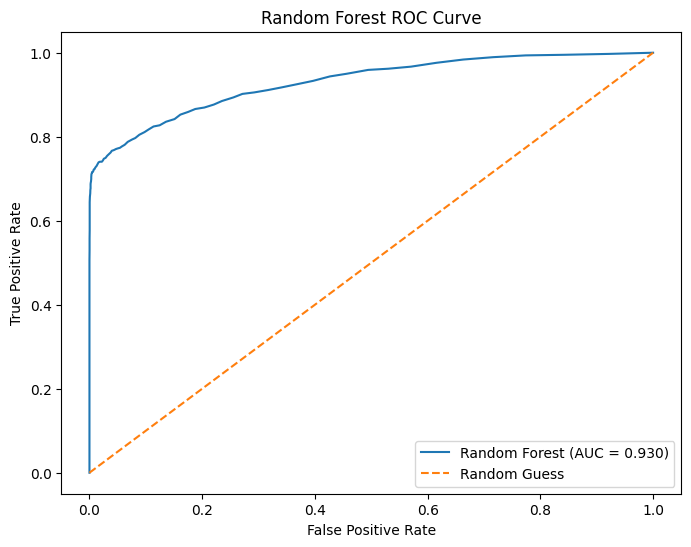

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Probability of High Risk (class 1)
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob_rf)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

print("ROC-AUC Score:", roc_auc)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.show()

In [ ]:
import joblib

# Save Random Forest evaluation data
joblib.dump(
    {
        "y_test": y_test.to_numpy(),
        "y_pred_rf": y_pred_rf,
        "y_prob_rf": y_prob_rf,
        "fpr": fpr,
        "tpr": tpr,
        "roc_auc": roc_auc,
        "cm": cm
    },
    "rf_evaluation.pkl"
)

print("Random Forest evaluation data saved successfully!")

Random Forest evaluation data saved successfully!


In [ ]:
import os

print(os.path.exists("rf_evaluation.pkl"))

True


In [ ]:
import joblib

eval_data = joblib.load("rf_evaluation.pkl")

print(eval_data.keys())

dict_keys(['y_test', 'y_pred_rf', 'y_prob_rf', 'fpr', 'tpr', 'roc_auc', 'cm'])


In [ ]:
!streamlit run test_bg.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/test_logs.txt 2>&1 &

In [ ]:
!pkill -9 -f streamlit

In [ ]:
%%writefile test_bg.py

import streamlit as st

st.set_page_config(
    page_title="Background Test",
    layout="wide"
)

st.title("Background Image Test")

st.image(
    "loan_risk_background.jpg",
    width="stretch"
)

st.success("If you can see the image above, the image file is working.")

Writing test_bg.py


In [ ]:
!streamlit run test_bg.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/test_logs.txt 2>&1 &

In [ ]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-use1c3-2i5ki3ejv3ktj-c.us-east1.prod.r.colab.dev


In [ ]:
!ls -lh /content/app.py

-rw-r--r-- 1 root root 32K Oct 25 10:18 /content/app.py


In [ ]:
!cp /content/app.py /content/app_backup.py

In [ ]:
!head -n 35 /content/app.py


import streamlit as st
import pandas as pd
import numpy as np
import joblib
import base64
import os
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix


# ============================================================
# PAGE CONFIG
# ============================================================

st.set_page_config(
    page_title="Intelligent Loan Risk Assessment",
    page_icon="🏦",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ============================================================
# LOAD MODEL FILES
# ============================================================

rf_model = joblib.load("/content/random_forest_model.pkl")
scaler = joblib.load("/content/scaler.pkl")
eval_data = joblib.load("/content/rf_evaluation.pkl")


# ============================================================
# LOAN GRADE MAPPING


In [ ]:
!pkill -9 -f streamlit

In [ ]:
!streamlit run app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/logs.txt 2>&1 &

In [ ]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-use1c3-2i5ki3ejv3ktj-c.us-east1.prod.r.colab.dev


In [ ]:
from pathlib import Path

path = Path("/content/app.py")
code = path.read_text()

print("Current app.py size:", len(code), "characters")
print("Home page setup ready.")

Current app.py size: 32560 characters
Home page setup ready.


In [ ]:
!grep -n 'st.title\|st.header\|Applicant Details' /content/app.py | head -15

451:    st.title(
589:    st.title(
607:        "## 👤 Applicant Details"
